Universidad Torcuato Di Tella

Licenciatura en Tecnología Digital

**Métodos Computacionales — Reconstrucción y regularización en imágenes tomográficas**

# **Trabajo Práctico — Ejercicio N°10: Reconstruir una imagen desconocida**

Resolvemos todas las importaciones necesarias para el correcto funcionamiento del código.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Para construir matrices disperas
from scipy.sparse import coo_matrix

# Para calcular autovalores específicos en matrices disperas
from scipy.sparse.linalg import eigsh

En los primeros ejercicios utilizamos un modelo binario, en el que cada entrada de $A$ indicaba solamente si el centro de un píxel pertenecía o no a un rayo. En este último ejercicio abandonaremos ese modelo simplificado y utilizaremos una matriz de proyección basada en la geometría de los rayos.

La entrada $a_rj$ representa la longitud del tramo del rayo $r$ contenido dentro del píxel $j$. Por lo tanto, todo píxel atravesado por el rayo contribuye a la medición de manera proporcional a la longitud recorrida en su interior:

$$
b_r = \sum_j a_{rj} x_j
$$

Los datos y la función de carga se encuentran en esta [carpeta de drive](https://drive.google.com/drive/folders/1HpzIhC8FguAjnscD0LctfESVCbHms8he).

El archivo `datos_tomografia_final_128.npz` contiene mediciones simuladas de una imagen desconocida de $128\times128$ píxeles. Incluye la resolución $n$, la matriz de proyección dispersa $A$, el vector de mediciones ruidosas $b$, los ángulos $θ_0, \dots,θ_{K−1}$, las posiciones de detector $s_0,\dots,s_{q−1}$ y una estimación del ruido. La imagen original permanecerá oculta hasta después de la entrega.

Las filas de $A$ y las componentes de $b$ están ordenadas primero por ángulo y luego por posición de detector. Por lo tanto, la fila $r = kq+j$ corresponde al rayo $(θ_k,s_j)$. Como $A$ es una matriz dispersa, deberá cargarse mediante la función provista en `cargar_datos_tomografia.py` y no deberá convertirse en una matriz densa.

1. Cargar los datos y determinar $K$ y $q$ a partir de las cantidades de ángulos y posiciones de detector. Verificar que $A \in \mathbb{R}^{Kq \times n^2}$ y que $b\in \mathbb{R}^{Kq}$.

In [2]:
from datos_reales.cargar_datos_tomografia import cargar_datos_tomografia

# Estructura: "A", "b", "n", "angulos", "posiciones_detector", "ruido_relativo", "desviacion_ruido", "norma_ruido_esperada"
tomografia = cargar_datos_tomografia(ruta="datos_reales/datos_tomografia_final_128.npz")

K = len(tomografia["angulos"])
q = len(tomografia["posiciones_detector"])
n = tomografia["n"]

print("Cantidad de ángulos:", K)
print("Cantidad de detectores:", q)

print(f"Dimensión de A esperada: ({K*q}, {n**2})")
print(f"Dimensión real: {np.shape(tomografia["A"])}")

Cantidad de ángulos: 90
Cantidad de detectores: 183
Dimensión de A esperada: (16470, 16384)
Dimensión real: (16470, 16384)


2. Organizar las mediciones en una matriz $S \in \mathbb{R}^{K\times q}$ utilizando $S_{kj} = b_{kq+j}$. Visualizar $S$ como un sinograma, indicando en sus ejes los valores de s y θ.

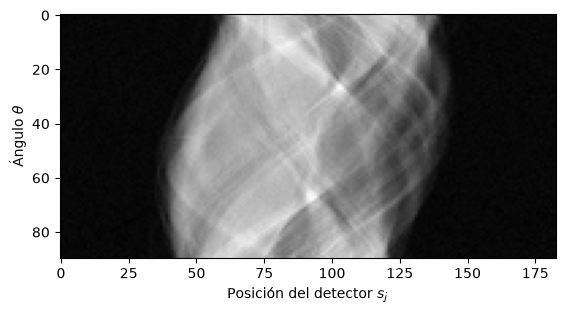

In [3]:
b = tomografia["b"]
S = b.reshape(K,q)

plt.xlabel(r"Posición del detector $s_j$")
plt.ylabel(r"Ángulo $\theta$")
plt.imshow(S, cmap='gray')

3. Adaptar `matriz_diferencias(n)` para construir $D$ como una matriz dispersa. Verificar que $D \in \mathbb{R}^{2n(n−1)\times n^2}$ y que cada fila contiene exactamente dos valores no nulos.

In [4]:
def matriz_diferencias_v2(n:int):
    '''
    Requiere: un entero n que representa la dimensión de la matriz sobre la cual se aplicará la matriz resultante.\n
    Devuelve: una matriz de diferencias D de tamaño 2n(n-1) x n².
    '''

    filas, cols, vals = [], [], []

    # La fila actual de la matriz D
    fila_actual = 0

    # Primero construimos el bloque Dh

    # Recorremos la imagen de forma vectorizada
    for i in range(n):
        for j in range(n-1):
            # Píxel X_ij = x_k
            k = i*n + j

            # Agregamos un elemento a D

            # La diferencia horizontal X_i,j+1 - X_ij en la misma fila
            filas.extend([fila_actual, fila_actual])

            # Para la columna k y k+1 hay -1 y 1, respectivamente
            vals.extend([-1, 1])
            cols.extend([k, k+1])

            # Pasamos a la siguiente fila de Dh
            fila_actual += 1

    # Luego construimos el bloque Dv
    for j in range(n):
        for i in range(n-1):
            # Píxel X_ij = x_k
            k = i*n + j

            # La diferencia vertical X_i+1,j - X_ij en la misma fila 
            filas.extend([fila_actual, fila_actual])
            
            # Para la columna k y k+n hay -1 y 1, respectivamente
            vals.extend([-1,1])
            cols.extend([k, k+n])

            # Pasamos a la siguiente fila de Dh
            fila_actual += 1

    D =  coo_matrix(arg1=(vals, (filas, cols)), shape=(2*n*(n-1),n**2)).tocsr()

    return D

D = matriz_diferencias_v2(n)

print(f"Dimensión de D esperada: ({2*n*(n-1)}, {n**2})")
print(f"Dimensión real: {np.shape(D)}") # type:ignore

Dimensión de D esperada: (32512, 16384)
Dimensión real: (32512, 16384)


4. Obtener una reconstrucción sin regularización, correspondiente a $\lambda = 0$, reutilizando el método de gradiente descendiente desarrollado anteriormente. Convertir el vector resultante en una imagen de $n \times n$ y visualizarla.

In [5]:
A = tomografia["A"]

In [6]:
# Definimos la función objetivo
def J(x:np.array, b:np.array, D:np.ndarray, lmbd:float): #type:ignore
    '''
    Requiere:

    - Un vector de solución parcial `x`.
    - Un vector de mediciones `b` sobre el cual comparar.
    - Una matriz `D` de diferencias.
    - Un float `lmbd` para regular la penalización por diferencias.

    Devuelve: un número flotante que resulta de evaluar la función objetivo con los parámetros dados.
    '''
    t1 = np.linalg.norm( (A @ x) - b )
    t2 = np.linalg.norm( D @ x )
    return 0.5 * (t1**2 + lmbd * (t2**2))

# Definimos el gradiente de la función objetivo
def grad_J(x:np.array, b:np.array, D:np.ndarray, lmbd:float): #type:ignore
    '''
    Requiere:

    - Un vector de solución parcial `x`.
    - Un vector de mediciones `b` sobre el cual comparar.
    - Una matriz `D` de diferencias.
    - Un float `lmbd` para regular la penalización por diferencias.

    Devuelve: un número flotante que resulta de evaluar el gradiente de la función objetivo.
    '''
    t1 = A.transpose() @ (A@x -b)
    t2 = lmbd * (D.transpose() @ D @ x)
    return t1 + t2

In [7]:
def gradiente_descendente_v4(x_0, bs, D, lmbd, alpha = 0.01, tolerancia = 0.0001, max_iter = 2000, verbose=False):
    '''
    Requiere:

    - Un vector de solución parcial `x`.
    - Un vector de mediciones `b` sobre el cual comparar.
    - Una matriz `D` de diferencias.
    - Un float `lmbd` para regular la penalización por diferencias.
    - (Opcional) Un float `alpha` que representa la tasa de aprendizaje (0.01 por defecto).
    - (Opcional) Un float `tolerancia` que funciona como criterio para seguir iterando (0.01 por defecto).
    - (Opcional) Un entero `max_iter` como cota superior de las iteraciones del método (1000 por defecto).
    - (Opcional) Un bool `verbose` para imprimir los resultados de las iteraciones (0.01 por defecto).

    Devuelve: un diccionario con las siguientes llaves.
    - `x`: La reconstrucción hallada.
    - `costos`: El vector con el registro de la variación del costo.
    - `normas`: El vector con el registro de la variación de la norma del gradiente.
    - `iters`: El número de iteraciones alcanzado.
    '''

    x_t   = x_0

    cost_log = list()
    grad_norm_log = list()

    iter  = 0

    while iter <= max_iter:
        
        x_tsig = x_t - alpha * grad_J(x=x_t, b=bs, D=D, lmbd=lmbd)

        cost_log.append( J(x=x_t, b=bs, D=D, lmbd=lmbd) )
        grad_norm_log.append(np.linalg.norm(grad_J(x=x_t, b=bs, D=D, lmbd=lmbd)))
        if verbose: print("Iteración", iter, "-> Mínimo hallado hasta ahora: ", J(x=x_t, b=bs, D=D, lmbd=lmbd), "-- Norma del gradiente: ", np.linalg.norm(grad_J(x=x_t, b=bs, D=D, lmbd=lmbd)))

        if abs( J(x=x_tsig, b=bs, D=D, lmbd=lmbd) - J(x=x_t, b=bs, D=D, lmbd=lmbd)) < tolerancia:
          break

        x_t = x_tsig
        iter = iter + 1

    res = {
       "x" : np.array(x_tsig),
       "costos" : cost_log,
       "normas" : grad_norm_log,
       "iters" : iter
    }

    return res

Tras varios intentos empleando diferentes valores de $\alpha$, no logramos converger. Por ello, decidimos buscar una cota inferior del hiperparámetro tal que el algoritmo pueda converger. En particular, empleamos lo hecho en el ejercicio (8) por lo que calculamos el mayor autovalor $\mu _{max}$ de $H_J(x)$.

Nosotros asumimos que $\lambda = 0 \implies J(x) = \frac{1}{2}||A_7 x - b_\sigma ||^2$. Luego, por lo hecho en el ejercicio (9), se deduce que $H_j = A^T A$:

In [8]:
# Calculamos la matriz hessiana (y la convertimos a una matriz dispersa)
hessiano = (A.T @ A).tocsr()

In [9]:
# Buscamos el máximo autovalor de H

# k=1 indica la cantidad de autovalores que buscamos
# which='LA' indica que buscamos el/los autovalores de mayor magnitud
umax = eigsh(hessiano, k=1, which='LA', return_eigenvectors=False)[0]
print("umax =", umax, "=> 2/umax =", 2 / umax)

umax = 11124.071 => 2/umax = 0.0001797903


Por ende, llegamos a que $0\lt\alpha\lt 0.00017979028$ para converger:

In [15]:
l0 = gradiente_descendente_v4(x_0=np.zeros(n*n), bs=b, D=D, lmbd=0, alpha=0.0001)

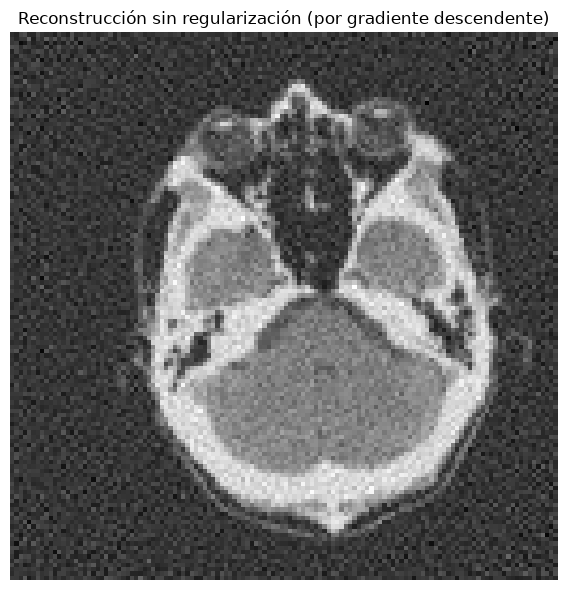

In [16]:
# Definimos la dimensión de la figura
plt.figure(figsize=(8, 6))

# Graficamos la imagen (en escala de grises)
plt.title("Reconstrucción sin regularización (por gradiente descendente)")
plt.imshow(l0["x"].reshape(n,n), cmap='gray')
# Quitamos los ejes
plt.axis("off")

# Ajustamos el layout
plt.tight_layout()

plt.show()

5. Obtener reconstrucciones regularizadas minimizando

$$
J_\lambda (x) = \frac{1}{2}(||Ax-b||^2 + \lambda ||Dx ||^2)
$$

Comenzar explorando $\lambda \in \{0,1,10,30,100\}$ y, si lo consideran necesario, probar valores adicionales.

In [ ]:
# Valores obligatorios
l1 = gradiente_descendente_v4(x_0=np.zeros(n*n), bs=b, D=D, lmbd=1, alpha=0.0001)
l10 = gradiente_descendente_v4(x_0=np.zeros(n*n), bs=b, D=D, lmbd=10, alpha=0.0001)
l30 = gradiente_descendente_v4(x_0=np.zeros(n*n), bs=b, D=D, lmbd=30, alpha=0.0001)
l100 = gradiente_descendente_v4(x_0=np.zeros(n*n), bs=b, D=D, lmbd=100, alpha=0.0001)

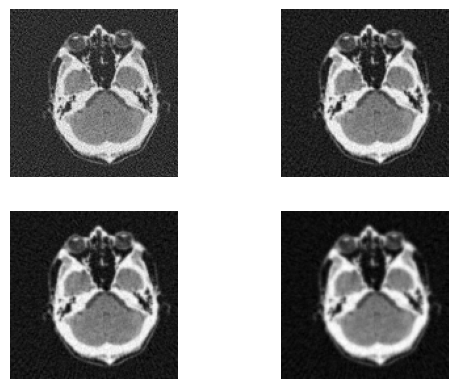

In [13]:
# Graficamos las imágenes (en escala de grises)
plt.subplot(2,2,1)
plt.imshow(l1["x"].reshape(n,n), cmap='gray')
plt.axis("off")

plt.subplot(2,2,2)
plt.imshow(l10["x"].reshape(n,n), cmap='gray')
plt.axis("off")

plt.subplot(2,2,3)
plt.imshow(l30["x"].reshape(n,n), cmap='gray')
plt.axis("off")

plt.subplot(2,2,4)
plt.imshow(l100["x"].reshape(n,n), cmap='gray')
plt.axis("off")

plt.show()

6. Para cada reconstrucción, registrar $\lambda$, la tasa de aprendizaje, la cantidad de iteraciones, la norma del residuo $||A\hat{x}_\lambda - b||$, la medida de variación $||D\hat{x}_\lambda||$ y sus valores mínimo y máximo. Comparar la norma del residuo con la estimación del ruido incluida en los datos.

In [23]:
A = tomografia["A"]
nr = [np.linalg.norm(A @ l0["x"] - b), np.linalg.norm(A @ l1["x"] - b), np.linalg.norm(A @ l10["x"] - b), np.linalg.norm(A @ l30["x"] - b), np.linalg.norm(A @ l100["x"] - b)]
mv = [np.linalg.norm(D @ l0["x"]), np.linalg.norm(D @ l1["x"]), np.linalg.norm(D @ l10["x"]), np.linalg.norm(D @ l30["x"]), np.linalg.norm(D @ l100["x"])]
E_nr = tomografia["norma_ruido_esperada"]

tabla = pd.DataFrame({
    "Lambda" : [0, 1, 10, 30, 100],
    "Tasa de aprendizaje" : [0.0001, 0.0001, 0.0001, 0.0001, 0.0001],
    "Iteraciones" : [l0["iters"], l1["iters"], l10["iters"], l30["iters"], l100["iters"]],
    "Norma del residuo" : nr,
    "Diferencia entre la norma del residuo y el ruido estimado" : [abs(nr[0]-E_nr), abs(nr[1]-E_nr), abs(nr[2]-E_nr), abs(nr[3]-E_nr), abs(nr[4]-E_nr)],
    "Medida de variación" : mv,
    "Mínimo" : [min(l0["x"]), min(l1["x"]), min(l10["x"]), min(l30["x"]), min(l100["x"])],
    "Máximo" : [max(l0["x"]), max(l1["x"]), max(l10["x"]), max(l30["x"]), max(l100["x"])]
})

print("Norma del ruido estimada:", E_nr)
tabla

Norma del ruido estimada: 75.96688842773438


,Lambda,Tasa de aprendizaje,Iteraciones,Norma del residuo,Diferencia entre la norma del residuo y el ruido estimado,Medida de variación,Mínimo,Máximo
0,0,0.0001,2001,43.619108,32.347780,28.534931,-0.337960,1.238349
1,1,0.0001,2001,45.329789,30.637100,24.620614,-0.263302,1.192210
2,10,0.0001,1135,55.392961,20.573928,18.496560,-0.150359,1.108403
3,30,0.0001,524,71.544154,4.422734,15.119448,-0.104161,1.076659
4,100,0.0001,293,102.646007,26.679118,11.467338,-0.062658,1.050569


7. Elegir la reconstrucción que consideren más adecuada sin conocer la imagen original. Presentar una figura con el sinograma construido, la reconstrucción sin regularización y al menos tres reconstrucciones regularizadas, utilizando una escala de color común. Justificar la elección considerando el ruido, el residuo, y la preservación de estructuras en la imagen.